# Notebook 1 — Better Retrievers

So far, every search worked the same way: embed the question, keep the k closest chunks.
That simple retriever failed in a few ways along the road: copies of the same text filled
the top k, unrelated chunks came back when nothing fit, a question in other words than the
handbook missed the right section, and filters hid inside the question. This notebook
fixes each of those failures with a smarter retriever.

**What you will learn**

1. **MMR**: keep near-duplicates out of the top k.
2. **Score threshold**: drop weak matches, and why no threshold is perfect.
3. **Multi-query**: search with several wordings of the question.
4. **Self-query**: let the model turn part of the question into metadata filters.
5. **Parent document**: search small pieces, give the model whole sections.
6. When to use which.

Older LangChain versions shipped ready-made classes for some of these. LangChain 1.x moved
them to a legacy package, so we build each one ourselves in a few lines. That also shows
exactly how they work.

**Before you start**

```bash
ollama pull nomic-embed-text   # embedding model
ollama pull gpt-oss:20b        # chat model, for multi-query, self-query, and answers
uv sync
```

Then choose the `.venv` Python kernel for this notebook. ⏱️ About 45 minutes.

## 1. Setup

The data is Brightleaf's knowledge base from Stages 2 and 3: the employee handbook, the IT
FAQ, and the company announcements. Every store lives in memory, in Chroma.

In [1]:
import json
from pathlib import Path
from typing import Literal

import chromadb
import matplotlib.pyplot as plt
from langchain_chroma import Chroma
from langchain_core.documents import Document
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate
from langchain_text_splitters import (
    Language,
    MarkdownHeaderTextSplitter,
    RecursiveCharacterTextSplitter,
)
from pydantic import BaseModel, Field

from roadmap import get_chat_model, get_embeddings
from roadmap.loaders import load_html, load_text

llm = get_chat_model()
embeddings = get_embeddings()
STAGE2_DATA = Path("../02-rag-fundamentals/data")
STAGE3_DATA = Path("../03-vector-databases/data")
ASSETS = Path("assets")
ASSETS.mkdir(exist_ok=True)

client = chromadb.EphemeralClient()  # in memory: every run starts fresh


def make_store(name: str, docs: list[Document]) -> Chroma:
    """A new in-memory Chroma collection with cosine distance."""
    if name in [collection.name for collection in client.list_collections()]:
        client.delete_collection(name)  # running the cell again replaces it
    return Chroma.from_documents(
        docs,
        embeddings,
        client=client,
        collection_name=name,
        collection_configuration={"hnsw": {"space": "cosine"}},
    )


def title(doc: Document) -> str:
    """A short label for a chunk: its first line, without the Markdown '#' signs."""
    first = doc.page_content.strip().splitlines()[0].lstrip("# ")
    return first if len(first) <= 36 else first[:34] + "..."

## 2. The baseline: the k closest chunks

The same setup as in Stage 2: the handbook and the IT FAQ, split at Markdown headings into
chunks of up to 500 characters. `as_retriever()` turns the store into the retriever we have
used so far.

In [2]:
handbook = load_text(STAGE2_DATA / "handbook.md")
faq = load_html(STAGE2_DATA / "it_faq.html")
splitter = RecursiveCharacterTextSplitter.from_language(
    Language.MARKDOWN, chunk_size=500, chunk_overlap=50
)
chunks = splitter.split_documents(handbook + faq)
store = make_store("brightleaf", chunks)

retriever = store.as_retriever(search_kwargs={"k": 3})
print(len(chunks), "chunks\n")
for doc in retriever.invoke("Who pays a parking fine?"):
    print("-", title(doc))

21 chunks

- 7. Company vehicles
- 9. Mobile phone policy
- 13. Contact


Every retriever in this notebook changes one step of this search: what goes in (the
question), or what comes out (the chunks).

![Where each retriever changes the search](assets/retriever_steps.svg)

## 3. MMR: keep near-duplicates out

A common accident: the same document gets indexed twice, for example once as Markdown and
once as PDF, or uploaded twice. Then every fact exists twice, and the copies fill the top k.
Let's index the handbook twice on purpose:

In [3]:
handbook_chunks = splitter.split_documents(handbook)
copies = [
    Document(page_content=chunk.page_content, metadata={"source": "handbook-copy.md"})
    for chunk in handbook_chunks
]
twice = make_store("handbook-twice", handbook_chunks + copies)

question = "What are the rules for company cars?"
print("Similarity search:")
for doc in twice.similarity_search(question, k=4):
    print(f"   {doc.metadata['source']:<17} {title(doc)}")

Similarity search:
   handbook.md       7. Company vehicles
   handbook-copy.md  7. Company vehicles
   handbook.md       9. Mobile phone policy
   handbook-copy.md  9. Mobile phone policy


Four results, but only two topics: each one twice. **MMR** (maximal marginal relevance)
picks the results one at a time. Each next pick must be close to the question **and**
different from the chunks already picked:

$$\text{score} = \lambda \cdot \text{similarity to the question} - (1 - \lambda) \cdot \text{highest similarity to a chunk already picked}$$

- `fetch_k`: how many candidates to look at first (here 20).
- `lambda_mult` ($\lambda$): 1 means "only relevance" (plain similarity search), 0 means
  "only diversity".

In [4]:
for weight in (0.7, 0.5):
    print(f"MMR with lambda_mult={weight}:")
    mmr_docs = twice.max_marginal_relevance_search(question, k=4, fetch_k=20, lambda_mult=weight)
    for doc in mmr_docs:
        print(f"   {doc.metadata['source']:<17} {title(doc)}")

MMR with lambda_mult=0.7:
   handbook.md       7. Company vehicles
   handbook-copy.md  7. Company vehicles
   handbook.md       9. Mobile phone policy
   handbook.md       12. Health and safety
MMR with lambda_mult=0.5:
   handbook.md       7. Company vehicles
   handbook.md       9. Mobile phone policy
   handbook.md       11. Code of conduct
   handbook.md       12. Health and safety


With 0.5, the copies are gone: the two right sections come first, followed by two new
topics. With 0.7 one copy is still there: the weight is a dial between relevance and
variety. The price of variety is visible too: the two new sections are less related to
cars. As a retriever:

```python
twice.as_retriever(search_type="mmr", search_kwargs={"k": 4, "fetch_k": 20, "lambda_mult": 0.5})
```

The better fix is still to keep duplicates out of the index (Stage 2, Notebook 2). MMR is
the safety net when you cannot.

## 4. Score threshold: drop weak matches

A retriever always returns k chunks, even when none of them fits (Stage 2, Notebook 1). A
**score threshold** drops every chunk whose relevance score is below a limit, so the
result can be empty. For our cosine store the relevance score is the cosine similarity.

Where should the limit be? Let's measure the best score of each question, for 19 questions
the knowledge base answers (the test set from Stage 2) and 10 it does not:

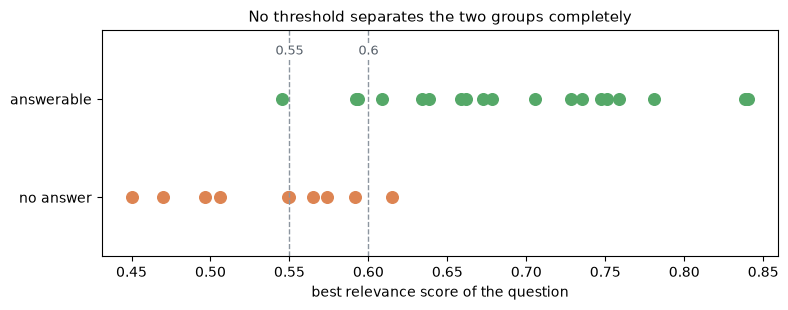

threshold 0.5: keeps 19 of 19 answerable questions, drops  3 of 10 without an answer
threshold 0.55: keeps 18 of 19 answerable questions, drops  6 of 10 without an answer
threshold 0.6: keeps 16 of 19 answerable questions, drops  9 of 10 without an answer
threshold 0.65: keeps 13 of 19 answerable questions, drops 10 of 10 without an answer


In [5]:
ANSWERABLE = [
    "Can I eat in company vehicles?",
    "How many vacation days do I get?",
    "How much is the learning budget?",
    "When do I need a doctor's note?",
    "How much can a hotel cost per night?",
    "Can I work from another country?",
    "Who pays a parking fine?",
    "How much of my phone costs are covered?",
    "How long is paid parental leave?",
    "Is there money for my home internet?",
    "What happens to unused vacation days?",
    "What should I do in case of fire?",
    "How do I reset my password?",
    "Do I need the VPN for email?",
    "What is the Wi-Fi password for visitors?",
    "How many color pages can I print?",
    "Are files on my laptop backed up?",
    "I clicked a link in a phishing email. What now?",
    "How often are laptops replaced?",
]
NO_ANSWER = [
    "Can I bring my dog to the office?",
    "What is the dress code?",
    "Is there a gym in the building?",
    "When is the summer party?",
    "Can I get a company credit card?",
    "What is the capital of France?",
    "Do we have a pension plan?",
    "Is lunch free in the canteen?",
    "How do I book a meeting room?",
    "Can I bring my children to work?",
]


def best_score(question: str) -> float:
    return store.similarity_search_with_relevance_scores(question, k=1)[0][1]


answerable = [best_score(q) for q in ANSWERABLE]
no_answer = [best_score(q) for q in NO_ANSWER]

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.scatter(answerable, [1] * len(answerable), s=70, color="#55A868", label="answer in the data")
ax.scatter(no_answer, [0] * len(no_answer), s=70, color="#DD8452", label="no answer in the data")
for limit in (0.55, 0.6):
    ax.axvline(limit, color="#8C959F", linestyle="--", linewidth=1)
    ax.text(
        limit,
        1.45,
        f"{limit}",
        ha="center",
        fontsize=9,
        color="#57606a",
        bbox={"facecolor": "white", "edgecolor": "none", "pad": 1},
    )
ax.set_yticks([0, 1], ["no answer", "answerable"])
ax.set_ylim(-0.6, 1.7)
ax.set_xlabel("best relevance score of the question")
ax.set_title("No threshold separates the two groups completely", fontsize=11)
fig.tight_layout()
fig.savefig(ASSETS / "score_threshold.png", dpi=120)
plt.show()

for limit in (0.5, 0.55, 0.6, 0.65):
    kept = sum(score >= limit for score in answerable)
    dropped = sum(score < limit for score in no_answer)
    print(
        f"threshold {limit}: keeps {kept:>2} of 19 answerable questions, "
        f"drops {dropped:>2} of 10 without an answer"
    )

The two groups overlap. "Who pays a parking fine?" has an answer but scores lower than "What
is the dress code?", which has none. Every threshold trades one mistake for the other:

- **Low** (0.5): keeps every answerable question, but drops few of the others.
- **High** (0.65): drops every question without an answer, but also loses a third of the
  good ones.

So use a **low** threshold to drop chunks that are clearly unrelated, and let the grounding
prompt (Stage 2, Notebook 2) handle the rest with "I don't know". Measure on your own data
before you pick the number; there is no general value.

In [6]:
threshold_retriever = store.as_retriever(
    search_type="similarity_score_threshold",
    search_kwargs={"score_threshold": 0.55, "k": 3},
)
for question in ["What is the capital of France?", "How do I reset my password?"]:
    docs = threshold_retriever.invoke(question)
    print(f"{question} -> {len(docs)} chunks: {[title(doc) for doc in docs]}")

No relevant docs were retrieved using the relevance score threshold 0.55


What is the capital of France? -> 0 chunks: []
How do I reset my password? -> 3 chunks: ['IT Help Desk FAQ', 'What is the guest Wi-Fi password?', 'Are my files backed up?']


LangChain prints a warning when nothing is left, but an empty result is useful: the app can
answer "I don't know" right away, without calling the model at all, like the food
recommender in Stage 3.

## 5. Multi-query: search with several wordings

In Stage 2, Notebook 1, this question missed the phone section: it says "phone bill" and
"Brightleaf pays", while the handbook says "phone costs are covered". Here is the miss again,
with the handbook alone and k=3, as back then:

In [7]:
handbook_store = make_store("handbook", handbook_chunks)
handbook_retriever = handbook_store.as_retriever(search_kwargs={"k": 3})

phone_question = "How much of the phone bill does Brightleaf pay?"
print([title(doc) for doc in handbook_retriever.invoke(phone_question)])

['Brightleaf pays a home office allo...', 'Brightleaf Employee Handbook', '1. Working hours']


**Multi-query** asks the model to write the question in other ways, searches with every
version, and keeps each chunk it finds once. A small retriever built from a prompt and
structured output (Stage 1):

In [8]:
class Queries(BaseModel):
    queries: list[str] = Field(description="3 short search queries")


def multi_query(instructions: str, base_retriever):
    """A retriever that searches with the question plus 3 versions the model writes."""
    prompt = ChatPromptTemplate.from_messages([("system", instructions), ("user", "{question}")])
    write_queries = prompt | llm.with_structured_output(Queries)

    def retrieve(question: str) -> list[Document]:
        queries = [question, *write_queries.invoke({"question": question}).queries]
        print("   searched:", queries[1:])
        found = {}
        for query in queries:
            for doc in base_retriever.invoke(query):
                found.setdefault(doc.page_content, doc)  # keep each chunk once
        return list(found.values())

    return retrieve


first_try = multi_query(
    "Write 3 different versions of the user's question. Use other words for the same thing. "
    "Keep each one short.",
    handbook_retriever,
)
print([title(doc) for doc in first_try(phone_question)])

   searched: ['What portion of the phone bill does Brightleaf cover?', 'How much does Brightleaf pay toward the phone bill?', 'What share of the phone bill is paid by Brightleaf?']
['Brightleaf pays a home office allo...', 'Brightleaf Employee Handbook', '1. Working hours', '7. Company vehicles']


The first version still misses. The model reworded the question, but kept its words: "phone
bill" and "Brightleaf". The company name matches many chunks and adds noise (Stage 2,
Notebook 3 showed the same for agent queries). Let's ask for the words the **handbook**
would use instead:

In [9]:
better = multi_query(
    "Write 3 short search queries that would find the answer to the user's question in an "
    "employee handbook. Use the words a handbook would use, not the words of the question, and "
    "leave out the company name.",
    handbook_retriever,
)
phone_docs = better(phone_question)
print([title(doc) for doc in phone_docs])

   searched: ['telephone expense reimbursement policy', 'mobile phone allowance coverage', 'company phone cost reimbursement']
['Brightleaf pays a home office allo...', 'Brightleaf Employee Handbook', '1. Working hours', '9. Mobile phone policy', '13. Contact', '6. Expenses and travel']


Now "9. Mobile phone policy" is found. With the right chunk in the context, the grounded
answer from Stage 2 gets it right:

In [10]:
answer_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You answer questions from Brightleaf employees, using only the context below. The "
            "answer may be a yes or a no, or may need a small step of reasoning from the context. "
            "Only if the context does not cover the question, say: I don't know."
            "\n\nContext:\n{context}",
        ),
        ("user", "{question}"),
    ]
)
answer_chain = answer_prompt | llm | StrOutputParser()


def answer(question: str, docs: list[Document]) -> str:
    context = "\n\n---\n\n".join(doc.page_content for doc in docs)
    return answer_chain.invoke({"context": context, "question": question})


print(answer(phone_question, phone_docs))

Brightleaf covers up to **40 EUR per month** of your phone bill.


Multi-query costs one extra model call per question, and it sends more chunks to the model:
here 6 different chunks instead of 3. Stage 4, Notebook 3 measures whether that
is worth it on the whole test set.

## 6. Self-query: filters hidden in the question

"What did IT announce in 2026?" contains two filters: the team and the year. A plain
search only sees the words. The company announcements from Stage 3 have both as metadata:

In [11]:
items = json.loads((STAGE3_DATA / "announcements.json").read_text(encoding="utf-8"))[
    "announcements"
]
announcements = [
    Document(
        page_content=f"{item['title']}. {item['text']}",
        metadata={"team": item["team"], "year": int(item["date"][:4]), "date": item["date"]},
    )
    for item in items
]
news = make_store("announcements", announcements)

it_question = "What did IT announce in 2026?"
for doc in news.similarity_search(it_question, k=3):
    print(f"   {doc.metadata['team']:<10} {doc.metadata['year']}  {title(doc)}")

   People     2026  Book your learning days. Remember ...
   IT         2026  New VPN app. A new VPN app replace...
   People     2026  New handbook version. Version 3.2 ...


Only one of the three results is from IT in 2026. **Self-query** lets the model split the
question into a topic and filters, with structured output. The example in the prompt matters:
without it, the model put "IT" into the topic instead of the team filter.

In [12]:
class SearchRequest(BaseModel):
    query: str = Field(description="a short search query about the topic only")
    team: Literal["IT", "People", "Facilities"] | None = Field(
        None, description="the team that made the announcement, if the question names one"
    )
    year: int | None = Field(None, description="the year, if the question names one")


request_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "Turn the user's question into a search request for company announcements: a short "
            "topic query, plus a team and a year filter when the question names them. For "
            "example, 'What did People announce about leave in 2025?' becomes query 'leave', team "
            "'People', year 2025.",
        ),
        ("user", "{question}"),
    ]
)
write_request = request_prompt | llm.with_structured_output(SearchRequest)


def to_where(request: SearchRequest) -> dict | None:
    """The Chroma filter for the request (Stage 3, Notebook 2), or None."""
    conditions = [{"team": request.team}] if request.team else []
    conditions += [{"year": request.year}] if request.year else []
    if not conditions:
        return None
    return conditions[0] if len(conditions) == 1 else {"$and": conditions}


def self_query(question: str, k: int = 3) -> list[Document]:
    request = write_request.invoke({"question": question})
    where = to_where(request)
    print(f"   query={request.query!r}  filter={where}")
    # An empty topic (the question was only filters) falls back to the question itself.
    return news.similarity_search(request.query or question, k=k, filter=where)


for question in [
    it_question,
    "What changed for passwords in 2025?",
    "Is the office closed over the holidays?",
]:
    print(question)
    for doc in self_query(question):
        print(f"      {doc.metadata['team']:<10} {doc.metadata['year']}  {title(doc)}")

What did IT announce in 2026?


   query=''  filter={'$and': [{'team': 'IT'}, {'year': 2026}]}
      IT         2026  New VPN app. A new VPN app replace...
      IT         2026  Phishing training. Every employee ...
What changed for passwords in 2025?


   query='passwords'  filter={'year': 2025}
      IT         2025  Longer passwords. Passwords for wo...
      Facilities 2025  Two more company cars. Two more el...
      Facilities 2025  Office closed over the holidays. T...
Is the office closed over the holidays?


   query='office closed holidays'  filter=None
      Facilities 2025  Office closed over the holidays. T...
      People     2026  Book your learning days. Remember ...
      People     2026  New handbook version. Version 3.2 ...


Each search now only sees the announcements that pass the filter, and a question without
a team or a year gets no filter at all. Two warnings:

- The model can get a filter wrong, and a wrong filter hides the right answer completely.
  Show the filter it used, as above.
- Rules that must always hold (a diet, an allergy, a user's permissions) do not belong in
  the question. Set them in code or in the user interface, like the filter panel of the
  Stage 3 food recommender.

## 7. Parent document: search small, answer with the whole section

Chunk size is a trade-off (Stage 2, Notebook 2): small chunks match a question precisely,
but carry little context; big chunks carry context, but match less precisely. The **parent
document** retriever does both: it searches small pieces, then gives the model the whole
section each piece came from.

In [13]:
header_splitter = MarkdownHeaderTextSplitter(
    headers_to_split_on=[("#", "title"), ("##", "section")], strip_headers=False
)
sections = header_splitter.split_text(handbook[0].page_content)  # the parents
piece_splitter = RecursiveCharacterTextSplitter(chunk_size=150, chunk_overlap=0)
pieces = [
    Document(page_content=text, metadata={"parent": number})  # remember the section
    for number, section in enumerate(sections)
    for text in piece_splitter.split_text(section.page_content)
]
pieces_store = make_store("handbook-pieces", pieces)
print(f"{len(sections)} sections, {len(pieces)} small pieces")


def parent_document(question: str, k: int = 3) -> tuple[list[Document], list[Document]]:
    """Search the small pieces, return them and the sections they belong to."""
    hits = pieces_store.similarity_search(question, k=k)
    parent_numbers = dict.fromkeys(hit.metadata["parent"] for hit in hits)  # unique, in order
    return hits, [sections[number] for number in parent_numbers]

14 sections, 48 small pieces


In [14]:
question = "Can I work from another country, and what do I have to do first?"
hits, parents = parent_document(question)

print("Small pieces found:")
for hit in hits:
    print("   ", hit.page_content.replace("\n", " ")[:90])
print("Sections they belong to:", [section.metadata.get("section") for section in parents])

print("\nAnswer from the small pieces:\n   ", answer(question, hits))
print("Answer from the whole sections:\n   ", answer(question, parents))

Small pieces found:
    so that people meet in person at least once a week.   Working from another country is allo
    ## 2. Remote work   You can work from home up to three days per week. Every team agrees on
    After parental leave, you can work part-time (between 20 and 32 hours per week) for up to 
Sections they belong to: ['2. Remote work', '5. Parental leave']



Answer from the small pieces:
    Yes, you can work from another country, but only for up to 20 working days per calendar year. The policy doesn’t specify what you need to do first, so I don’t know the exact steps.


Answer from the whole sections:
    Yes. You can work from another country for up to 20 working days per calendar year. Before you travel, you must notify People Operations at least two weeks in advance because of tax and insurance rules.


The small pieces found the right place, but they cut the rule in two: the model could only
answer half of the question (the limit), not what to do first. The whole "2. Remote work"
section holds both parts: the limit and what to do before you travel.

Store the parents somewhere the app can look them up by id. Here a Python list is enough;
a real app keeps them in a database next to the vector store.

## 8. Which retriever when?

| Problem you see | Retriever | Cost |
|---|---|---|
| Copies or near-copies fill the top k | MMR | almost none; may add less related chunks |
| Unrelated chunks come back when nothing fits | Score threshold | none; can drop good chunks, so keep it low |
| Questions use other words than the documents | Multi-query | one extra model call, more chunks in the prompt |
| Questions name filters ("IT", "2026") | Self-query | one extra model call; a wrong filter hides answers |
| Matches are precise but the answer needs more text | Parent document | longer prompts |

They combine: for example, multi-query over a store of small pieces, followed by a parent
lookup. Start with the simple retriever, look at what it gets wrong, and add only the fix for
that.

## 9. Summary

| Idea | What it means | In code |
|---|---|---|
| MMR | Relevant **and** different from what is already picked | `search_type="mmr"`, `fetch_k`, `lambda_mult` |
| Score threshold | Drop chunks below a relevance score; the result can be empty | `search_type="similarity_score_threshold"` |
| Multi-query | Search with several wordings, keep each chunk once | structured output: a list of queries |
| Self-query | The model turns part of the question into metadata filters | structured output → `filter=` |
| Parent document | Search small pieces, return their whole sections | a `parent` id in each piece's metadata |

**Remember:** every retriever here fixes one specific failure. Find the failure first, by
looking at what the retriever returns.

➡️ **Next:** [Notebook 2 — Keyword search, hybrid search, and reranking](02_llamaindex_retrievers.ipynb)